# Progress 3 Poin 5 dan 6
## Pengaturan parameter dan hasil modelling
Kontribusi Andini Papa Sulima. Notebook lanjutan mandiri berdasarkan proyek kelompok commit 7cfd844e72b78874c6e232025b714bbab11b2040. Jalankan Run All dari folder CSV. Bukti hasil disimpan pada folder bukti. Notebook utama dan model aplikasi tidak ditimpa.

Business Understanding: membentuk profil pelanggan untuk pemasaran per segmen dan menentukan segmen pelanggan baru bagi Manajer CRM. Notebook terbaru menetapkan keterbedaan profil, konsistensi data uji, dan kegunaan rekomendasi tanpa ambang numerik. Target lama pada materi Progress 1, Silhouette > 0,50, tetap dilaporkan statusnya.

In [1]:
from pathlib import Path
import hashlib, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy, matplotlib
from IPython.display import display
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from threadpoolctl import threadpool_limits
thread_limits = threadpool_limits(limits=1)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.max_columns', 20)
BUKTI = Path('bukti')
BUKTI.mkdir(exist_ok=True)
DATA = Path('E_Commerce_Dataset.csv')
SEED = 42
FEATURES = ['Tenure','WarehouseToHome','HourSpendOnApp','OrderCount','CashbackAmount','Total_Orders_Engagement']
IMPUTE = ['Tenure','WarehouseToHome','HourSpendOnApp','OrderAmountHikeFromlastYear','CouponUsed','OrderCount','DaySinceLastOrder']
versions = {'python':platform.python_version(),'scikit-learn':sklearn.__version__,'pandas':pd.__version__,'numpy':np.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__}
print('Versi:', versions)
print('SHA256 data:', hashlib.sha256(DATA.read_bytes()).hexdigest())

Versi: {'python': '3.13.12', 'scikit-learn': '1.9.0', 'pandas': '3.0.2', 'numpy': '2.4.2', 'scipy': '1.17.1', 'matplotlib': '3.10.9'}
SHA256 data: d6c9891ae75fc4e364cad222e92828616d72544c82cbeb7cb1cbe1048bcf5aa2


## Data masukan dari Progress 2
Enam fitur mengikuti notebook kelompok. Hasil encoding, CustomerID, dan Churn tidak masuk model. OrderCount muncul sendiri serta dalam Total_Orders_Engagement sehingga dimensi aktivitas belanja mendapat penekanan tambahan.

Urutan diperbaiki: split pelanggan terlebih dahulu, hitung median dan fit scaler pada data latih saja. Data uji tidak dipakai memilih k atau linkage. Outlier dipertahankan. Median latih dibandingkan dengan median seluruh data untuk memeriksa dampak perubahan urutan.

In [2]:
raw = pd.read_csv(DATA)
raw.columns = raw.columns.str.strip()
assert raw.shape == (5630,20) and raw.CustomerID.is_unique
train_idx,test_idx = train_test_split(raw.index,test_size=.2,random_state=SEED)
medians = raw.loc[train_idx,IMPUTE].median()
median_check = pd.DataFrame({'Median seluruh':raw[IMPUTE].median(),'Median latih':medians})
display(median_check)
clean = raw.copy()
clean[IMPUTE] = clean[IMPUTE].fillna(medians)
clean['PreferredPaymentMode'] = clean.PreferredPaymentMode.replace({'CC':'Credit Card','COD':'Cash on Delivery'})
clean['Total_Orders_Engagement'] = clean.OrderCount + clean.CouponUsed
X_train,X_test = clean.loc[train_idx,FEATURES],clean.loc[test_idx,FEATURES]
scaler = StandardScaler()
train = pd.DataFrame(scaler.fit_transform(X_train),columns=FEATURES,index=train_idx)
test = pd.DataFrame(scaler.transform(X_test),columns=FEATURES,index=test_idx)
assert not set(train_idx)&set(test_idx)
assert train.shape==(4504,6) and test.shape==(1126,6)
assert np.isfinite(train.to_numpy()).all() and np.isfinite(test.to_numpy()).all()
assert np.allclose(train.mean(),0,atol=1e-12)
assert np.allclose(scaler.mean_,X_train.mean())
display(pd.DataFrame({'Subset':['Latih','Uji'],'Pelanggan':[len(train),len(test)],'Fitur':[6,6]}))
print('Nilai kosong awal:',raw.isna().sum().sum(),'| setelah:',clean.isna().sum().sum())
print('Median latih sama dengan pendekatan sebelumnya:',np.array_equal(median_check.iloc[:,0],median_check.iloc[:,1]))
median_check.to_csv(BUKTI/'median_imputasi.csv')

,Median seluruh,Median latih
Tenure,9.0,9.0
WarehouseToHome,14.0,14.0
HourSpendOnApp,3.0,3.0
OrderAmountHikeFromlastYear,15.0,15.0
CouponUsed,1.0,1.0
OrderCount,2.0,2.0
DaySinceLastOrder,3.0,3.0


,Subset,Pelanggan,Fitur
0,Latih,4504,6
1,Uji,1126,6


Nilai kosong awal: 1856 | setelah: 0
Median latih sama dengan pendekatan sebelumnya: True


# Poin 5 Pengaturan Parameter
## 5.1 Rancangan percobaan
| Model | Parameter yang diuji | Pengaturan tetap |
|---|---|---|
| K-Means | k 2 sampai 10 | init k-means++, n_init 10, max_iter 300, tol 0,0001, algorithm lloyd, random_state 42 |
| Hierarchical | single, complete, average, ward; k 2 sampai 5 | Jarak Euclidean, data latih dan scaler yang sama |

random_state menjaga reproduksibilitas. n_init mencoba sepuluh inisialisasi dan memilih inertia terkecil. Seed tidak dicari untuk mengejar skor tinggi. Silhouette dihitung pada seluruh data latih.

Penilaian mempertimbangkan Silhouette, pola penurunan inertia, dan ukuran klaster. Inertia cenderung turun saat k bertambah, sehingga tidak cukup dipakai sendirian. Ukuran klaster menjadi diagnosis kegunaan CRM tanpa ambang kelulusan yang dikarang.

,k,Inertia,Silhouette latih,Ukuran klaster,Klaster terkecil,Klaster terbesar (%),Iterasi,Penurunan inertia (%)
0,2,20075.5650,0.3752,"[3779, 725]",725,83.9032,7,NaN
1,3,16412.7372,0.2821,"[2862, 643, 999]",643,63.5435,13,18.2452
2,4,14160.0908,0.2526,"[735, 605, 2323, 841]",605,51.5764,8,13.7250
3,5,12359.2304,0.2460,"[760, 1772, 633, 552, 787]",552,39.3428,9,12.7179
4,6,11219.1950,0.2495,"[504, 1702, 633, 723, 752, 190]",190,37.7886,22,9.2242
5,7,10328.0280,0.2445,"[1413, 485, 678, 551, 732, 462, 183]",183,31.3721,27,7.9432
6,8,9577.2546,0.2430,"[564, 1048, 180, 473, 455, 668, 477, 639]",180,23.2682,24,7.2693
7,9,9080.0930,0.2492,"[471, 567, 1025, 383, 233, 657, 436, 547, 185]",185,22.7575,17,5.1911
8,10,8677.4211,0.2472,"[546, 452, 330, 370, 632, 562, 987, 227, 237, ...",161,21.9139,22,4.4347


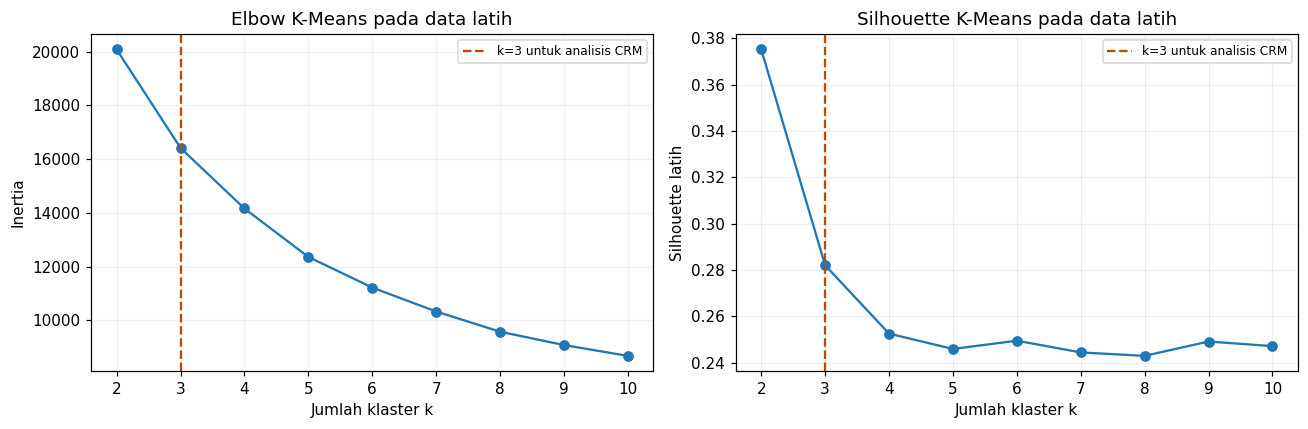

In [3]:
km_models,km_rows = {},[]
for k in range(2,11):
    m = KMeans(n_clusters=k,init='k-means++',n_init=10,max_iter=300,tol=1e-4,algorithm='lloyd',random_state=SEED).fit(train)
    sizes = np.bincount(m.labels_,minlength=k)
    km_models[k] = m
    km_rows.append({'k':k,'Inertia':m.inertia_,'Silhouette latih':silhouette_score(train,m.labels_),'Ukuran klaster':sizes.tolist(),'Klaster terkecil':int(sizes.min()),'Klaster terbesar (%)':sizes.max()/len(train)*100,'Iterasi':m.n_iter_})
km_grid = pd.DataFrame(km_rows)
km_grid['Penurunan inertia (%)'] = -km_grid.Inertia.pct_change()*100
display(km_grid.round(4))
km_grid.to_csv(BUKTI/'percobaan_kmeans.csv',index=False)
fig,axs = plt.subplots(1,2,figsize=(12,4))
for ax,col,title in zip(axs,['Inertia','Silhouette latih'],['Elbow K-Means','Silhouette K-Means']):
    ax.plot(km_grid.k,km_grid[col],marker='o')
    ax.set(title=title+' pada data latih',xlabel='Jumlah klaster k',ylabel=col,xticks=range(2,11))
    ax.axvline(3,color='#BA4A00',linestyle='--',label='k=3 untuk analisis CRM')
    ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(BUKTI/'01_parameter_kmeans.png',dpi=180); plt.show()

## 5.2 Parameter Hierarchical
Matriks linkage dihitung sekali per metode, lalu dipotong pada k yang diuji. Skor dibaca bersama ukuran anggota. Single linkage dapat membentuk satu kelompok raksasa dan kelompok sangat kecil. Ward meminimalkan kenaikan variasi dalam kelompok dan menggunakan jarak Euclidean.

,Linkage,k,Silhouette latih,Ukuran klaster,Klaster terkecil,Klaster terbesar (%)
0,single,2,0.7664,"[4502, 2]",2,99.9556
1,single,3,0.5888,"[4501, 2, 1]",1,99.9334
2,single,4,0.5161,"[4499, 2, 2, 1]",1,99.8890
3,single,5,0.5055,"[4497, 2, 2, 2, 1]",1,99.8446
4,complete,2,0.7664,"[4502, 2]",2,99.9556
5,complete,3,0.4974,"[4358, 144, 2]",2,96.7584
6,complete,4,0.2296,"[3906, 452, 144, 2]",2,86.7229
7,complete,5,0.2136,"[3440, 452, 466, 144, 2]",2,76.3766
8,average,2,0.7664,"[4502, 2]",2,99.9556
9,average,3,0.4897,"[4498, 4, 2]",2,99.8668


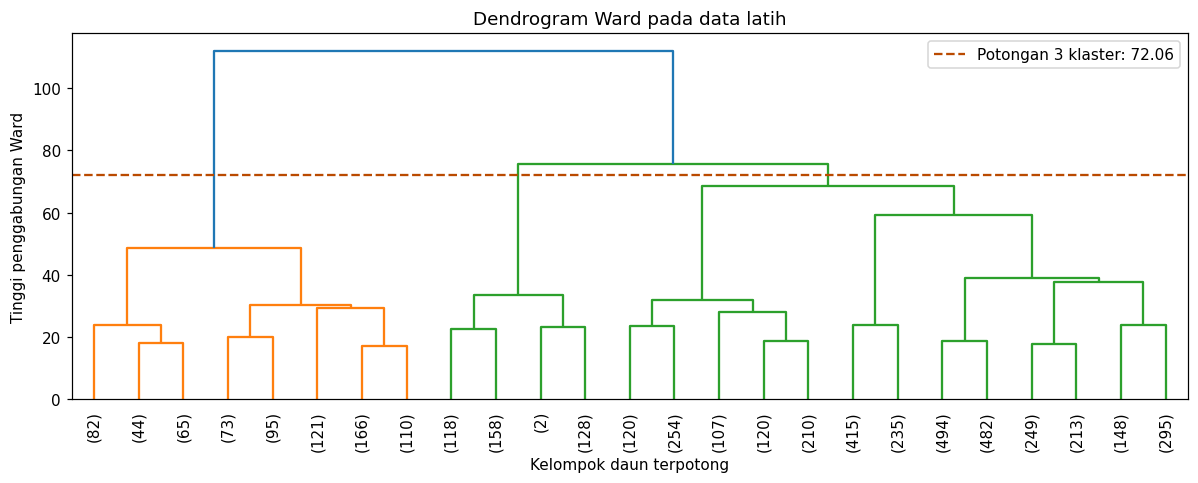

In [4]:
hc_rows,hc_labels,matrices = [],{},{}
for method in ['single','complete','average','ward']:
    Z = linkage(train.to_numpy(),method=method,metric='euclidean')
    matrices[method] = Z
    for k in range(2,6):
        labels = cut_tree(Z,n_clusters=k).ravel()
        sizes = np.bincount(labels,minlength=k)
        hc_labels[(method,k)] = labels
        hc_rows.append({'Linkage':method,'k':k,'Silhouette latih':silhouette_score(train,labels),'Ukuran klaster':sizes.tolist(),'Klaster terkecil':int(sizes.min()),'Klaster terbesar (%)':sizes.max()/len(train)*100})
hc_grid = pd.DataFrame(hc_rows)
display(hc_grid.round(4))
hc_grid.to_csv(BUKTI/'percobaan_hierarchical.csv',index=False)
Z = matrices['ward']
height = (Z[-3,2]+Z[-2,2])/2
fig,ax = plt.subplots(figsize=(11,4.5))
dendrogram(Z,truncate_mode='lastp',p=25,leaf_rotation=90,ax=ax)
ax.axhline(height,color='#BA4A00',linestyle='--',label=f'Potongan 3 klaster: {height:.2f}')
ax.set(title='Dendrogram Ward pada data latih',xlabel='Kelompok daun terpotong',ylabel='Tinggi penggabungan Ward')
ax.legend(); fig.tight_layout(); fig.savefig(BUKTI/'02_dendrogram_ward.png',dpi=180); plt.show()

In [5]:
best_km = km_grid.loc[km_grid['Silhouette latih'].idxmax()]
best_hc = hc_grid.loc[hc_grid['Silhouette latih'].idxmax()]
km3 = km_grid.set_index('k').loc[3]
ward3 = hc_grid[(hc_grid.Linkage=='ward')&(hc_grid.k==3)].iloc[0]
display(km_grid[km_grid.k.isin([2,3])].round(4))
display(hc_grid[hc_grid.k==3].round(4))
print('k K-Means dengan Silhouette tertinggi:',int(best_km.k))
print('Konfigurasi Hierarchical dengan Silhouette tertinggi:',best_hc.to_dict())

,k,Inertia,Silhouette latih,Ukuran klaster,Klaster terkecil,Klaster terbesar (%),Iterasi,Penurunan inertia (%)
0,2,20075.5650,0.3752,"[3779, 725]",725,83.9032,7,NaN
1,3,16412.7372,0.2821,"[2862, 643, 999]",643,63.5435,13,18.2452


,Linkage,k,Silhouette latih,Ukuran klaster,Klaster terkecil,Klaster terbesar (%)
1,single,3,0.5888,"[4501, 2, 1]",1,99.9334
5,complete,3,0.4974,"[4358, 144, 2]",2,96.7584
9,average,3,0.4897,"[4498, 4, 2]",2,99.8668
13,ward,3,0.3018,"[3342, 756, 406]",406,74.2007


k K-Means dengan Silhouette tertinggi: 2
Konfigurasi Hierarchical dengan Silhouette tertinggi: {'Linkage': 'single', 'k': 2, 'Silhouette latih': 0.7663621598123015, 'Ukuran klaster': [4502, 2], 'Klaster terkecil': 2, 'Klaster terbesar (%)': 99.95559502664298}


### Bukti tambahan memilih tiga profil
Bandingkan rata-rata fitur data latih pada k=2 dan k=3 serta tabulasi silang keanggotaannya. Ini menjelaskan informasi tambahan saat jumlah kelompok dinaikkan. Perubahan jumlah kelompok tidak membuktikan tiga kelompok adalah solusi terbaik secara universal.

In [6]:
profiles_k = {}
for k in [2,3]:
    profiles_k[k] = X_train.assign(Klaster=km_models[k].labels_).groupby('Klaster')[FEATURES].mean()
    profiles_k[k].insert(0,'Jumlah pelanggan latih',np.bincount(km_models[k].labels_,minlength=k))
compare_profile = pd.concat(profiles_k,names=['k','Klaster'])
display(compare_profile.round(2))
compare_profile.to_csv(BUKTI/'profil_k2_vs_k3.csv')
transition = pd.crosstab(km_models[2].labels_,km_models[3].labels_,rownames=['Klaster k=2'],colnames=['Klaster k=3'])
display(transition)
transition.to_csv(BUKTI/'keanggotaan_k2_vs_k3.csv')
assert transition.to_numpy().sum()==len(train)
print('Silhouette k=3 lebih rendah:',km_grid.loc[km_grid.k==3,'Silhouette latih'].iloc[0]<km_grid.loc[km_grid.k==2,'Silhouette latih'].iloc[0])

Jumlah pelanggan latih  Tenure  WarehouseToHome  HourSpendOnApp  \
k Klaster                                                                    
2 0                          3779    9.62            15.63            2.93   
  1                           725   12.90            15.49            2.99   
3 0                          2862    6.04            15.44            2.91   
  1                           643   11.81            15.38            3.00   
  2                           999   20.85            16.25            2.97   

           OrderCount  CashbackAmount  Total_Orders_Engagement  
k Klaster                                                       
2 0              1.89          171.43                     3.12  
  1              8.64          206.92                    13.04  
3 0              1.85          155.01                     3.01  
  1              9.05          199.63                    13.64  
  2              2.32          226.07                     3.86

Klaster k=3,0,1,2
Klaster k=2,,,
0,2858,1,920
1,4,642,79


Silhouette k=3 lebih rendah: True


**Cara membaca:** pada k=2, kelompok mayoritas menggabungkan pelanggan dengan masa keanggotaan dan pola belanja yang beragam. Pada k=3, profil frekuensi tinggi tetap terlihat sementara profil aktivitas rendah dan masa keanggotaan panjang menjadi lebih terpisah secara deskriptif. Lihat rata-rata serta tabulasi silang di atas sebagai bukti; tiga kelompok tidak sepenuhnya merupakan pecahan bersarang dari dua kelompok karena K-Means dilatih ulang.

Pada grid Ward, k=2 juga memiliki skor lebih tinggi daripada k=3. Jumlah tiga kelompok dipertahankan untuk membandingkan profil pada resolusi bisnis yang sama. Grid linkage menunjukkan skor >0,50 dapat muncul bersama satu kelompok yang memuat hampir semua pelanggan, sehingga target numerik saja tidak cukup.

## 5.3 Keputusan parameter
Analisis mempertahankan K-Means k=3 dan Ward k=3 untuk memeriksa tiga profil CRM serta menjaga kesinambungan dengan proyek kelompok. Ini pilihan dengan kompromi, bukan klaim k=3 memaksimalkan Silhouette.

- K-Means k=2 memiliki Silhouette tertinggi pada grid ini. Tiga kelompok memberi profil lebih rinci untuk ditelaah dengan skor lebih rendah. Elbow membantu membaca tambahan penurunan inertia, tanpa membuktikan optimum tunggal.
- Ward k=3 menjadi pembanding dengan jumlah segmen sama. Linkage lain perlu dinilai bersama ukuran kelompok, bukan langsung dipilih berdasarkan skor.
- Nomor klaster hanya label. Nama diturunkan dari profil aktual.
- K-Means menyediakan predict untuk pelanggan baru. AgglomerativeClustering tidak menyediakan predict bawaan.

Data uji baru dievaluasi setelah pilihan tiga kelompok ditetapkan. Tidak ada penyesuaian parameter berdasarkan skor uji. Artefak aplikasi tidak diganti.

# Poin 6 Hasil Modelling
## 6.1 Model final dan metrik
Silhouette menilai kekompakan dan pemisahan, bukan persentase akurasi. Skor latih dan uji dihitung pada himpunan yang berbeda. Kedekatannya menjadi pemeriksaan awal, bukan jaminan konsistensi lintas waktu.

In [7]:
final_model = km_models[3]
test_labels = final_model.predict(test)
sil_test = silhouette_score(test,test_labels)
ward_model = AgglomerativeClustering(n_clusters=3,linkage='ward',metric='euclidean')
ward_labels = ward_model.fit_predict(train)
assert adjusted_rand_score(ward_labels,hc_labels[('ward',3)])==1.0
metric_table = pd.DataFrame([
    {'Model':'K-Means','Subset':'Latih','N':len(train),'k':3,'Silhouette':km3['Silhouette latih']},
    {'Model':'K-Means','Subset':'Uji','N':len(test),'k':3,'Silhouette':sil_test},
    {'Model':'Ward','Subset':'Latih','N':len(train),'k':3,'Silhouette':silhouette_score(train,ward_labels)}])
display(metric_table.round(4))
metric_table.to_csv(BUKTI/'metrik_model.csv',index=False)
assert final_model.n_iter_<final_model.max_iter
print('Target lama Silhouette >0,50 untuk K-Means final:', 'tercapai' if km3['Silhouette latih']>.5 else 'belum tercapai')

,Model,Subset,N,k,Silhouette
0,K-Means,Latih,4504,3,0.2821
1,K-Means,Uji,1126,3,0.2799
2,Ward,Latih,4504,3,0.3018


Target lama Silhouette >0,50 untuk K-Means final: belum tercapai


In [8]:
assignments = pd.Series(index=raw.index,dtype='float64',name='Klaster')
assignments.loc[train_idx] = final_model.labels_
assignments.loc[test_idx] = test_labels
assert assignments.notna().all()
clean['Klaster'] = assignments.astype(int)
subset = pd.Series('Latih',index=raw.index)
subset.loc[test_idx] = 'Uji'
sizes = pd.crosstab(clean.Klaster,subset).reindex(columns=['Latih','Uji'])
sizes['Total'] = sizes.sum(axis=1)
sizes['Proporsi seluruh (%)'] = sizes.Total/len(clean)*100
assert sizes.Total.sum()==len(raw)
display(sizes.round(2))
sizes.to_csv(BUKTI/'jumlah_anggota.csv')
profile = clean.groupby('Klaster')[FEATURES+['CouponUsed','DaySinceLastOrder']].mean()
profile['Churn historis (%)'] = clean.groupby('Klaster').Churn.mean()*100
low,active,loyal = int(profile.OrderCount.idxmin()),int(profile.OrderCount.idxmax()),int(profile.Tenure.idxmax())
assert len({low,active,loyal})==3,'Periksa penamaan profil secara manual.'
names = {low:'Aktivitas belanja rendah',active:'Frekuensi pesanan tinggi',loyal:'Masa keanggotaan panjang'}
profile.insert(0,'Profil deskriptif',pd.Series(names))
display(profile.round(2))
profile.to_csv(BUKTI/'profil_klaster.csv')
ward_profile = clean.loc[train_idx].assign(Ward=ward_labels).groupby('Ward')[FEATURES].mean()
display(pd.Series(np.bincount(ward_labels),name='Pelanggan latih Ward').to_frame())
display(ward_profile.round(2))
ward_profile.to_csv(BUKTI/'profil_ward_latih.csv')
clean[['CustomerID','Klaster']].assign(Subset=subset).to_csv(BUKTI/'keanggotaan_pelanggan.csv',index=False)

col_0,Latih,Uji,Total,Proporsi seluruh (%)
Klaster,,,,
0,2862,737,3599,63.93
1,643,149,792,14.07
2,999,240,1239,22.01


,Profil deskriptif,Tenure,WarehouseToHome,HourSpendOnApp,OrderCount,CashbackAmount,Total_Orders_Engagement,CouponUsed,DaySinceLastOrder,Churn historis (%)
Klaster,,,,,,,,,,
0,Aktivitas belanja rendah,6.09,15.40,2.91,1.84,155.13,2.99,1.15,3.57,21.20
1,Frekuensi pesanan tinggi,11.90,15.25,2.99,9.07,200.50,13.61,4.54,7.57,16.04
2,Masa keanggotaan panjang,20.76,16.26,2.98,2.31,226.51,3.86,1.56,5.05,4.68


,Pelanggan latih Ward
0,3342
1,756
2,406


,Tenure,WarehouseToHome,HourSpendOnApp,OrderCount,CashbackAmount,Total_Orders_Engagement
Ward,,,,,,
0,8.15,15.84,2.95,1.91,159.49,3.13
1,12.54,13.72,2.93,8.20,205.58,12.41
2,22.16,17.21,2.80,2.07,269.54,3.46


## 6.2 Visualisasi hasil
Sebaran hanya menampilkan dua dari enam fitur model. Seluruh pelanggan tampil: label latih dari fit, label uji dari predict. Heatmap menyajikan rata-rata enam fitur pada skala standar dengan scaler latih.

Churn dipakai sesudah pembentukan klaster sebagai konteks historis, bukan fitur pelatihan atau prediksi risiko individu. Profil cashback tinggi belum membuktikan profit tinggi.

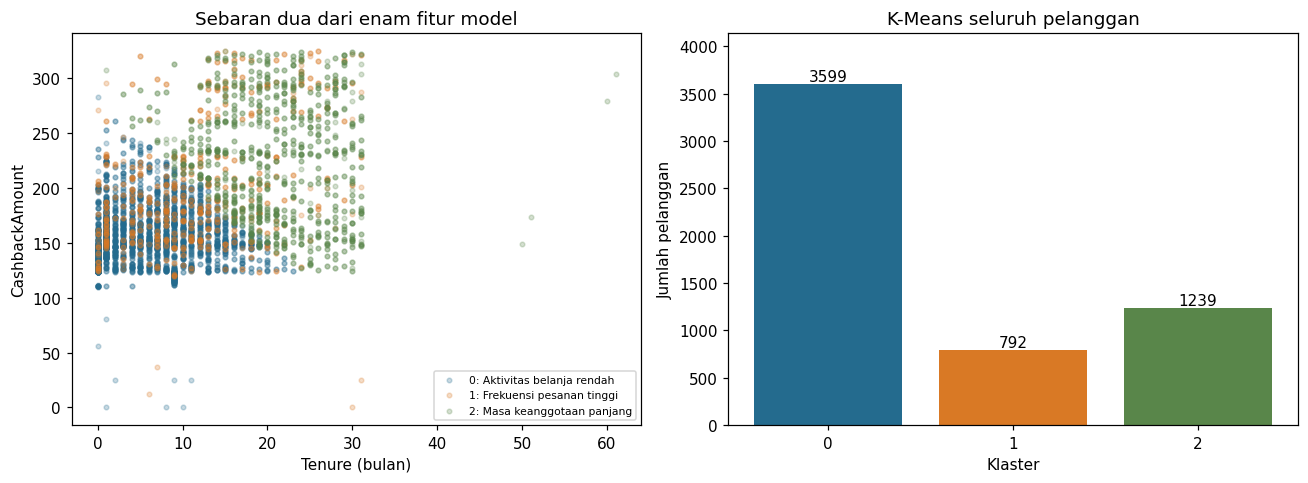

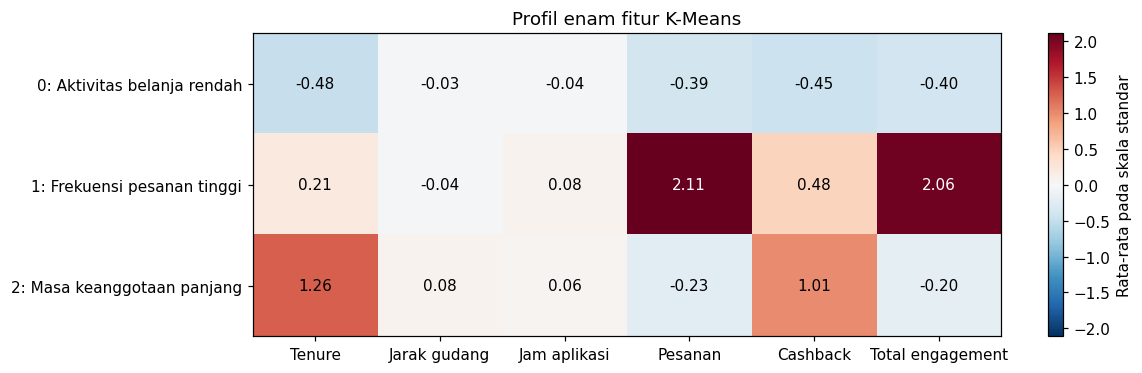

In [9]:
colors = ['#246B8E','#D97925','#59864A']
fig,axs = plt.subplots(1,2,figsize=(12,4.5))
for c in range(3):
    g = clean[clean.Klaster==c]
    axs[0].scatter(g.Tenure,g.CashbackAmount,s=9,alpha=.25,color=colors[c],label=f'{c}: {names[c]}',rasterized=True)
axs[0].set(title='Sebaran dua dari enam fitur model',xlabel='Tenure (bulan)',ylabel='CashbackAmount')
axs[0].legend(fontsize=7)
axs[1].bar(sizes.index.astype(str),sizes.Total,color=colors)
axs[1].set(title='K-Means seluruh pelanggan',xlabel='Klaster',ylabel='Jumlah pelanggan',ylim=(0,sizes.Total.max()*1.15))
for c,v in sizes.Total.items(): axs[1].text(c,v+35,str(v),ha='center')
fig.tight_layout(); fig.savefig(BUKTI/'03_hasil_klaster.png',dpi=180); plt.show()
scaled_all = pd.DataFrame(scaler.transform(clean[FEATURES]),columns=FEATURES,index=clean.index)
heat = scaled_all.groupby(clean.Klaster).mean()
limit = np.abs(heat.to_numpy()).max()
fig,ax = plt.subplots(figsize=(11,3.5))
im = ax.imshow(heat,cmap='RdBu_r',vmin=-limit,vmax=limit,aspect='auto')
ax.set_xticks(range(6),['Tenure','Jarak gudang','Jam aplikasi','Pesanan','Cashback','Total engagement'])
ax.set_yticks(range(3),[f'{c}: {names[c]}' for c in range(3)])
for i in range(3):
    for j in range(6):
        ax.text(j,i,f'{heat.iloc[i,j]:.2f}',ha='center',va='center',color='white' if abs(heat.iloc[i,j])>limit*.6 else 'black')
fig.colorbar(im,ax=ax,label='Rata-rata pada skala standar')
ax.set_title('Profil enam fitur K-Means')
fig.tight_layout(); fig.savefig(BUKTI/'04_profil_fitur.png',dpi=180); plt.show()

In [10]:
summary = {'source_commit':'7cfd844e72b78874c6e232025b714bbab11b2040','dataset_sha256':hashlib.sha256(DATA.read_bytes()).hexdigest(),
    'versions':versions,'features':FEATURES,'best_kmeans_k':int(best_km.k),
    'best_kmeans_silhouette':float(best_km['Silhouette latih']),'selected_k':3,
    'kmeans_train_silhouette':float(km3['Silhouette latih']),'kmeans_test_silhouette':float(sil_test),
    'ward_train_silhouette':float(metric_table.iloc[2].Silhouette),
    'cluster_sizes':{str(c):int(v) for c,v in sizes.Total.items()},
    'cluster_names':{str(c):n for c,n in names.items()},
    'old_target_050_reached':bool(km3['Silhouette latih']>.5)}
(BUKTI/'ringkasan.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(summary,ensure_ascii=False,indent=2))

{
  "source_commit": "7cfd844e72b78874c6e232025b714bbab11b2040",
  "dataset_sha256": "d6c9891ae75fc4e364cad222e92828616d72544c82cbeb7cb1cbe1048bcf5aa2",
  "versions": {
    "python": "3.13.12",
    "scikit-learn": "1.9.0",
    "pandas": "3.0.2",
    "numpy": "2.4.2",
    "scipy": "1.17.1",
    "matplotlib": "3.10.9"
  },
  "features": [
    "Tenure",
    "WarehouseToHome",
    "HourSpendOnApp",
    "OrderCount",
    "CashbackAmount",
    "Total_Orders_Engagement"
  ],
  "best_kmeans_k": 2,
  "best_kmeans_silhouette": 0.3752088865872891,
  "selected_k": 3,
  "kmeans_train_silhouette": 0.28206970996523945,
  "kmeans_test_silhouette": 0.2798945127652416,
  "ward_train_silhouette": 0.30182184437264525,
  "cluster_sizes": {
    "0": 3599,
    "1": 792,
    "2": 1239
  },
  "cluster_names": {
    "0": "Aktivitas belanja rendah",
    "1": "Frekuensi pesanan tinggi",
    "2": "Masa keanggotaan panjang"
  },
  "old_target_050_reached": false
}


## Interpretasi untuk Business Understanding
Aktivitas rendah menjadi kandidat aktivasi pembelian berikutnya. Frekuensi tinggi menjadi kandidat penawaran produk terkait dan evaluasi kupon. Masa keanggotaan panjang menjadi kandidat apresiasi pelanggan lama. Rekomendasi adalah hipotesis yang perlu diuji, belum bukti efektivitas promosi.

Keterbatasan: pemisahan klaster terbatas; k=3 merupakan kompromi; evaluasi memakai satu split; fitur turunan menambah bobot aktivitas; nilai ekstrem dapat memengaruhi centroid; data uji sudah pernah diperiksa pada proyek kelompok sehingga bukan holdout baru. Median diperbaiki menjadi fit pada latih saja dan hasil perbandingannya tampil di atas. Target Silhouette >0,50 pada materi lama harus dilaporkan apa adanya.

Integrasi: notebook ini menyediakan blok poin 5 dan 6 untuk disertakan sebagai notebook lanjutan pada repository. Tabel metrik juga bisa dipakai teman penanggung jawab poin 7 dan 8. Semua hasil berasal dari eksekusi baru, bukan menyalin output lama. Tidak ada file model .pkl yang ditulis.